# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
from itertools import combinations
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(42)

## Step 2 — Upload the dataset

Use the course file `Lab_11_QnA_Dataset_Download.csv`. Run this cell and select that CSV if Colab prompts for an upload. In Jupyter, put the CSV in the notebook's working directory, then run all cells in order.

In [3]:
dataset_path = Path("Lab_11_QnA_Dataset_Download.csv")
alt_dataset_path = Path("Lab_11_QnA_Dataset.csv")

# Fallback to the uploaded file without _Download in its name
if not dataset_path.is_file() and alt_dataset_path.is_file():
    dataset_path = alt_dataset_path

if not dataset_path.is_file():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError(f"Place {dataset_path.name} in the notebook's working directory.") from error
    files.upload()

# Re-check in case the user uploaded the alternative name
if not dataset_path.is_file() and alt_dataset_path.is_file():
    dataset_path = alt_dataset_path

if not dataset_path.is_file():
    raise FileNotFoundError(f"Upload the course CSV as {dataset_path.name}.")

df = pd.read_csv(dataset_path)
if not {"question", "answer_id"}.issubset(df.columns):
    raise ValueError("The CSV must contain the question and answer_id columns.")
if df.empty or df[["question", "answer_id"]].isna().any().any():
    raise ValueError("The CSV must contain questions and answer IDs in every row.")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
# Use the same tokens to encode questions and label the attention charts.
tokenized_questions = [re.findall(r"\w+", question.lower()) for question in df["question"]]
if any(not words for words in tokenized_questions):
    raise ValueError("Every question must contain at least one word.")

vocabulary = dict.fromkeys(word for words in tokenized_questions for word in words)
word_to_id = {word: index for index, word in enumerate(vocabulary, start=1)}
sequences = [torch.tensor([word_to_id[word] for word in words]) for words in tokenized_questions]
X = pad_sequence(sequences, batch_first=True, padding_value=0)

# Cross-entropy expects class indices from 0 to the number of classes minus 1.
class_indices, answer_ids = pd.factorize(df["answer_id"])
y = torch.tensor(class_indices, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self, vocab_size, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x == 0, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights


model = RNN(len(word_to_id) + 1, len(answer_ids))

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
model.train()

for epoch in range(1, 51):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = criterion(logits, y)
    loss.backward()
    optimizer.step()

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:02d}/50 | Loss: {loss.item():.4f}")

model.eval()

Epoch 01/50 | Loss: 2.5033
Epoch 10/50 | Loss: 1.8043
Epoch 20/50 | Loss: 1.0658
Epoch 30/50 | Loss: 0.5188
Epoch 40/50 | Loss: 0.2025
Epoch 50/50 | Loss: 0.0710


RNN(
  (emb): Embedding(226, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)

## Step 6 — See attention

Each bar corresponds to one token position. The highlighted bar has the highest attention weight for that question. Padding is excluded, so the weights across the displayed words sum to one.

In [7]:
@torch.no_grad()
def plot_attention(row_index):
    question = df.at[row_index, "question"]
    words = tokenized_questions[row_index]
    _, weights = model(X[row_index:row_index + 1])
    token_weights = weights[0, :len(words)]
    top_index = token_weights.argmax().item()
    scores = token_weights.tolist()
    top_word, top_weight = words[top_index], scores[top_index]

    positions = list(range(len(words)))
    colors = ["#4F46A5" if i == top_index else "#A6B6E3" for i in positions]
    fig, ax = plt.subplots(figsize=(max(6, 0.52 * len(words)), 2.7))
    ax.bar(positions, scores, color=colors)
    ax.set_xticks(positions, words, rotation=35, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Attention weight")
    ax.set_title(f"Row {row_index} · {question}", loc="left", wrap=True)
    fig.tight_layout()
    plt.show()
    print(f"Highest attention: '{top_word}' (word {top_index + 1}, weight {top_weight:.3f})")
    return top_word

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

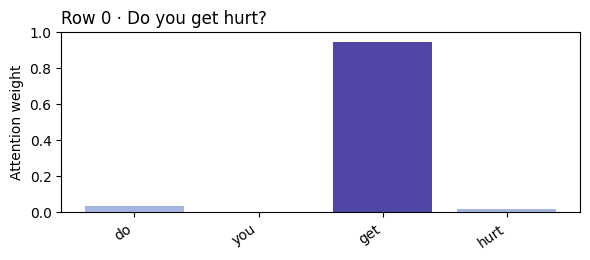

Highest attention: 'get' (word 3, weight 0.945)
'get' is a candidate clue to the question's topic or intent.


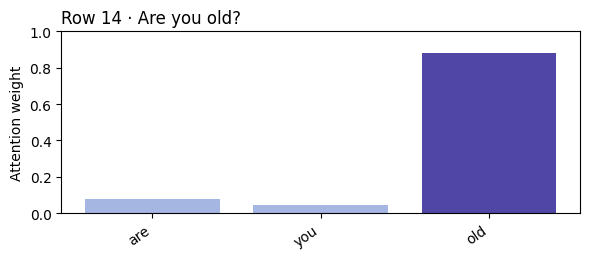

Highest attention: 'old' (word 3, weight 0.881)
'old' is a candidate clue to the question's topic or intent.


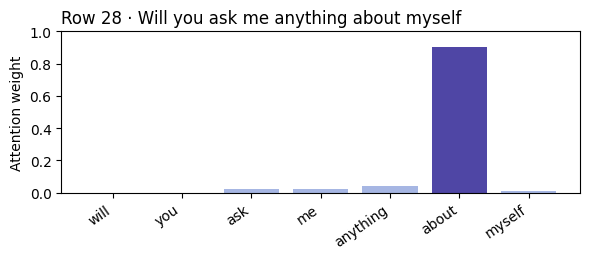

Highest attention: 'about' (word 6, weight 0.906)
'about' is a candidate clue to the question's topic or intent.


In [8]:
common_words = set("""
    a an the i me my we us our you your he she it its they them this that these those
    do does did is are am was were be been being can could will would should may might
    have has had to of in on for at with from by as and or but what which who when where
    why how there ever some any if s t
""".split())

# Take one question from each of the first three answer groups.
task1_rows = df.drop_duplicates("answer_id").head(3).index
for row_index in task1_rows:
    top_word = plot_attention(row_index)
    if top_word in common_words:
        print(f"'{top_word}' is a common word. The weight applies to its RNN state, which can carry context from earlier words.")
    else:
        print(f"'{top_word}' is a candidate clue to the question's topic or intent.")

**Task 1 discussion.** “Old” directly indicates that the question is about age. “Get” helps express the meaning when read with “hurt.” In the third question, “about” received the highest weight, but by itself it gives little information about the question’s meaning. The RNN can carry context from earlier words into the state at that position.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Shared answer ID: 0
Expected answer: I don't have a body.
Shared content words: get, hurt


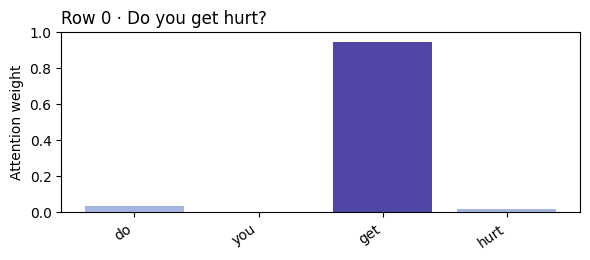

Highest attention: 'get' (word 3, weight 0.945)


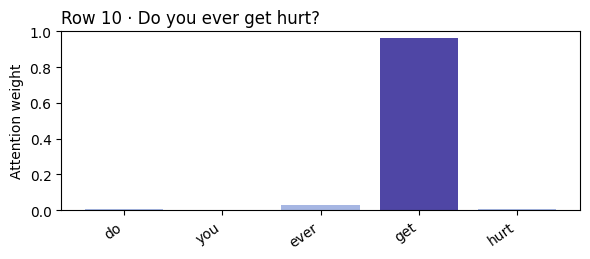

Highest attention: 'get' (word 4, weight 0.962)
Both questions give the most attention to 'get'.


In [9]:
# Look for similarly worded questions that have the same expected answer.
content_words = [set(words) - common_words for words in tokenized_questions]
best_pair = None
best_score = -1.0

for _, group in df.groupby("answer_id", sort=False):
    for left, right in combinations(group.index, 2):
        if tokenized_questions[left] == tokenized_questions[right]:
            continue
        shared = content_words[left] & content_words[right]
        all_content = content_words[left] | content_words[right]
        similarity = len(shared) / len(all_content) if all_content else 0.0
        if similarity > best_score:
            best_pair, best_score = (left, right), similarity

if best_pair is None:
    raise ValueError("The dataset needs two differently worded questions with the same answer ID.")

left, right = best_pair
print(f"Shared answer ID: {df.at[left, 'answer_id']}")
if "answer" in df.columns:
    print(f"Expected answer: {df.at[left, 'answer']}")
print("Shared content words:", ", ".join(sorted(content_words[left] & content_words[right])) or "none")
first_word = plot_attention(left)
second_word = plot_attention(right)

if first_word == second_word:
    print(f"Both questions give the most attention to '{first_word}'.")
else:
    print(f"The top words differ: '{first_word}' and '{second_word}'.")

**Task 2 discussion.** The model gave the highest attention to “get” in both “Do you get hurt?” (0.945) and “Do you ever get hurt?” (0.962). Adding “ever” shifted the position of “get,” but the model still gave the highest weight to the same word.